# Import Library

In [7]:
import os
import time
import joblib
import librosa
import librosa.display
import soundfile as sf
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

---
# Tahap 1: Pengecekan & Validasi Dataset (*Data Understanding / Inventory*)
Pada tahap awal ini, kita memeriksa seluruh **200 file `.wav`** (`100 asli_human` dan `100 ai_manipulasi`) untuk memastikan:
1. **Keseimbangan Kelas (*Class Balance*):** Jumlah sampel tiap kelas seimbang.
2. **Keseragaman Spesifikasi Teknis:** Seluruh file memiliki *Sampling Rate* (`16.000 Hz`), jumlah sampel (`480.000` titik), dan durasi (`30,00 detik`) yang seragam.
3. **Integritas Sinyal Audio:** Tidak ada file yang rusak (*corrupt*), mengandung `NaN`, atau hening total (*silent audio*).

1. RINGKASAN JUMLAH DATA & KESEIMBANGAN KELAS (CLASS BALANCE)
 label         kelas  jumlah_file sr_unik  durasi_min  durasi_max  total_menit  rata2_max_amp  rata2_rms  jumlah_valid
     0    asli_human          100 [16000]        30.0        30.0         50.0         0.2113     0.0240           100
     1 ai_manipulasi          100 [16000]        30.0        30.0         50.0         0.1703     0.0218           100

2. STATUS VALIDASI INTEGRITAS AUDIO
Total seluruh file diperiksa : 200 file
Total file valid & bersih    : 200 file
Total file rusak / bermasalah: 0 file

5 Baris Pertama & 5 Baris Terakhir Tabel Inventaris:


,nama_file,kelas,label,sr,jumlah_sampel,durasi_detik,max_amplitude,rms_energy,valid
0,audio_001.wav,asli_human,0,16000,480000,30.0,0.1990,0.0216,True
1,audio_002.wav,asli_human,0,16000,480000,30.0,0.2123,0.0213,True
2,audio_003.wav,asli_human,0,16000,480000,30.0,0.2504,0.0212,True
3,audio_004.wav,asli_human,0,16000,480000,30.0,0.1712,0.0216,True
4,audio_005.wav,asli_human,0,16000,480000,30.0,0.1677,0.0206,True
195,audio_096.wav,ai_manipulasi,1,16000,480000,30.0,0.1406,0.0227,True
196,audio_097.wav,ai_manipulasi,1,16000,480000,30.0,0.1489,0.0214,True
197,audio_098.wav,ai_manipulasi,1,16000,480000,30.0,0.1333,0.0215,True
198,audio_099.wav,ai_manipulasi,1,16000,480000,30.0,0.1495,0.0200,True
199,audio_100.wav,ai_manipulasi,1,16000,480000,30.0,0.1576,0.0202,True


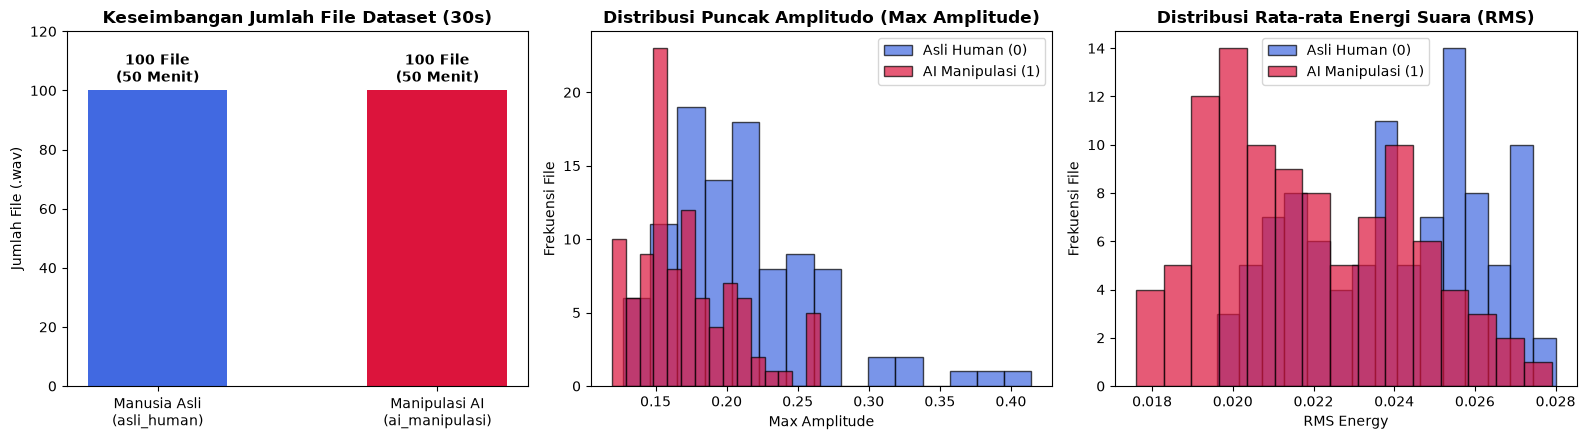

In [3]:
base_dir = '../../data/dataset_audio_kaggle'
kelas_map = {
    'asli_human': 0,
    'ai_manipulasi': 1
}

data_inventaris = []
file_bermasalah = []

for nama_kelas, label_id in kelas_map.items():
    folder_path = os.path.join(base_dir, nama_kelas)
    daftar_wav = sorted([f for f in os.listdir(folder_path) if f.endswith('.wav')])

    for nama_file in daftar_wav:
        full_path = os.path.join(folder_path, nama_file)
        try:
            y, sr_file = sf.read(full_path, dtype='float32')
            jumlah_sampel = len(y)
            durasi_detik  = jumlah_sampel / sr_file
            max_amp       = float(np.max(np.abs(y)))
            rms_val       = float(np.sqrt(np.mean(y**2)))
            ada_nan       = bool(np.isnan(y).any() or np.isinf(y).any())
            is_silent     = bool(max_amp < 1e-4)

            status_valid = (sr_file == 16000) and (abs(durasi_detik - 30.0) < 0.01) and (not ada_nan) and (not is_silent)
            if not status_valid:
                file_bermasalah.append((nama_kelas, nama_file, sr_file, durasi_detik, max_amp))

            data_inventaris.append({
                'nama_file': nama_file,
                'kelas': nama_kelas,
                'label': label_id,
                'sr': sr_file,
                'jumlah_sampel': jumlah_sampel,
                'durasi_detik': round(durasi_detik, 2),
                'max_amplitude': round(max_amp, 4),
                'rms_energy': round(rms_val, 4),
                'valid': status_valid
            })
        except Exception as e:
            file_bermasalah.append((nama_kelas, nama_file, str(e)))

df_inv = pd.DataFrame(data_inventaris)

print('==============================================================')
print('1. RINGKASAN JUMLAH DATA & KESEIMBANGAN KELAS (CLASS BALANCE)')
print('==============================================================')
ringkasan_kelas = df_inv.groupby(['label', 'kelas']).agg(
    jumlah_file=('nama_file', 'count'),
    sr_unik=('sr', lambda x: list(x.unique())),
    durasi_min=('durasi_detik', 'min'),
    durasi_max=('durasi_detik', 'max'),
    total_menit=('durasi_detik', lambda x: round(x.sum() / 60, 1)),
    rata2_max_amp=('max_amplitude', lambda x: round(x.mean(), 4)),
    rata2_rms=('rms_energy', lambda x: round(x.mean(), 4)),
    jumlah_valid=('valid', 'sum')
).reset_index()
print(ringkasan_kelas.to_string(index=False))

print('\n==============================================================')
print('2. STATUS VALIDASI INTEGRITAS AUDIO')
print('==============================================================')
print(f'Total seluruh file diperiksa : {len(df_inv)} file')
print(f'Total file valid & bersih    : {df_inv["valid"].sum()} file')
print(f'Total file rusak / bermasalah: {len(file_bermasalah)} file')

print('\n5 Baris Pertama & 5 Baris Terakhir Tabel Inventaris:')
display(pd.concat([df_inv.head(5), df_inv.tail(5)]))

# ==============================================================
# 3. VISUALISASI TAHAP 1 (MATPLOTLIB)
# ==============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Keseimbangan Kelas (Class Balance)
counts = df_inv['kelas'].value_counts()
bars = axes[0].bar(['Manusia Asli\n(asli_human)', 'Manipulasi AI\n(ai_manipulasi)'], [counts['asli_human'], counts['ai_manipulasi']], color=['royalblue', 'crimson'], width=0.5)
axes[0].set_title('Keseimbangan Jumlah File Dataset (30s)', fontweight='bold')
axes[0].set_ylabel('Jumlah File (.wav)')
axes[0].set_ylim(0, 120)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3, f'{int(bar.get_height())} File\n(50 Menit)', ha='center', fontweight='bold')

# Plot 2: Distribusi Max Amplitude
axes[1].hist(df_inv[df_inv['label']==0]['max_amplitude'], bins=15, alpha=0.7, label='Asli Human (0)', color='royalblue', edgecolor='black')
axes[1].hist(df_inv[df_inv['label']==1]['max_amplitude'], bins=15, alpha=0.7, label='AI Manipulasi (1)', color='crimson', edgecolor='black')
axes[1].set_title('Distribusi Puncak Amplitudo (Max Amplitude)', fontweight='bold')
axes[1].set_xlabel('Max Amplitude')
axes[1].set_ylabel('Frekuensi File')
axes[1].legend()

# Plot 3: Distribusi RMS Energy
axes[2].hist(df_inv[df_inv['label']==0]['rms_energy'], bins=15, alpha=0.7, label='Asli Human (0)', color='royalblue', edgecolor='black')
axes[2].hist(df_inv[df_inv['label']==1]['rms_energy'], bins=15, alpha=0.7, label='AI Manipulasi (1)', color='crimson', edgecolor='black')
axes[2].set_title('Distribusi Rata-rata Energi Suara (RMS)', fontweight='bold')
axes[2].set_xlabel('RMS Energy')
axes[2].set_ylabel('Frekuensi File')
axes[2].legend()

plt.tight_layout()
plt.show()

---
# Tahap 2: Segmentasi Audio (30 Detik $\rightarrow$ 6 Segmen @ 5 Detik) & Ekstraksi Fitur Librosa
Setiap **1 file induk berdurasi 30 detik** dibagi menjadi **6 segmen berdurasi 5 detik** (`detik 0–5`, `5–10`, `10–15`, `15–20`, `20–25`, `25–30`), lalu diekstrak **48 fitur audio Librosa** untuk setiap segmen:
- **Kelas `asli_human` (`0`):** 100 file $\times$ 6 segmen = **600 baris data**
- **Kelas `ai_manipulasi` (`1`):** 100 file $\times$ 6 segmen = **600 baris data**
- **Output Tabel CSV:** `fitur_audio_5s.csv` (**1.200 baris $\times$ 53 kolom**)

Memulai segmentasi 5 detik & ekstraksi fitur untuk 200 file induk...


c:\Users\ASUS\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated and will be removed in a future release
  "class": algorithms.Blowfish,
c:\Users\ASUS\anaconda3\Lib\site-packages\numba\np\ufunc\dufunc.py:359: NumbaWarning: Compilation requested for previously compiled argument types ((complex64,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)


  Progress: 25/200 file selesai (26.3 detik)
  Progress: 50/200 file selesai (31.5 detik)
  Progress: 75/200 file selesai (36.7 detik)
  Progress: 100/200 file selesai (42.0 detik)
  Progress: 125/200 file selesai (47.1 detik)
  Progress: 150/200 file selesai (52.3 detik)
  Progress: 175/200 file selesai (57.6 detik)
  Progress: 200/200 file selesai (61.9 detik)

SELESAI! TABEL FITUR SEGMEN 5 DETIK BERHASIL DISIMPAN:
File Output : ../../data/dataset_audio_kaggle\fitur_audio_5s.csv
Ukuran Tabel: 1200 baris x 54 kolom (600 Asli vs 600 AI)

Contoh 6 Segmen (5 Detik) dari File Pertama (audio_001.wav):


,id_sampel,file_induk,segmen_ke,durasi_detik,rms_mean,zcr_mean,f0_std,mfcc_8_mean,label
0,asli_human_audio_001_seg1,audio_001.wav,1,5,0.013955,0.067019,7.322242,-5.484699,0
1,asli_human_audio_001_seg2,audio_001.wav,2,5,0.021849,0.093535,32.651165,-6.805510,0
2,asli_human_audio_001_seg3,audio_001.wav,3,5,0.017732,0.134305,13.323370,-6.055473,0
3,asli_human_audio_001_seg4,audio_001.wav,4,5,0.019516,0.098779,27.622335,-7.716300,0
4,asli_human_audio_001_seg5,audio_001.wav,5,5,0.019679,0.109033,29.534050,-7.388360,0
5,asli_human_audio_001_seg6,audio_001.wav,6,5,0.021873,0.071012,16.379986,-11.109921,0


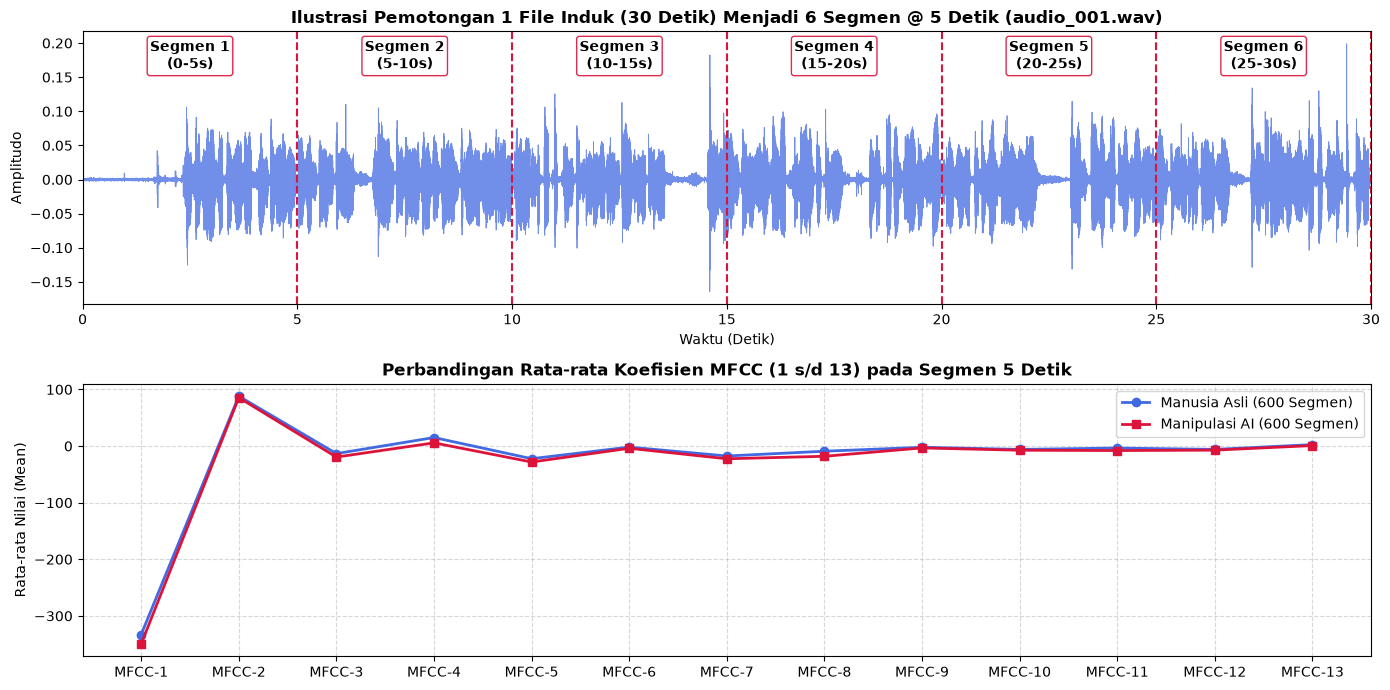

In [4]:
base_dir = '../../data/dataset_audio_kaggle'
out_dir  = '../../data/dataset_audio_kaggle'

def ekstrak_fitur_segmen(y_seg, sr, f0_seg):
    """Mengekstrak 48 fitur audio dari 1 segmen suara berdurasi 5 detik."""
    # 1. Time-Domain Features
    rms = librosa.feature.rms(y=y_seg)[0]
    zcr = librosa.feature.zero_crossing_rate(y=y_seg)[0]
    silence_ratio = float(np.mean(rms < 0.01) * 100.0)
    skew_val = float(stats.skew(y_seg))
    kurt_val = float(stats.kurtosis(y_seg))

    # 2. Frequency / Spectral Features
    S = np.abs(librosa.stft(y_seg))
    centroid  = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)[0]
    rolloff   = librosa.feature.spectral_rolloff(S=S, sr=sr)[0]
    flatness  = librosa.feature.spectral_flatness(S=S)[0]
    contrast  = librosa.feature.spectral_contrast(S=S, sr=sr)

    # 3. Pitch / Frekuensi Dasar Pita Suara (F0)
    voiced_mask = rms[:len(f0_seg)] > 0.01
    f0_voiced = f0_seg[voiced_mask] if np.any(voiced_mask) else f0_seg
    f0_mean   = float(np.mean(f0_voiced))
    f0_std    = float(np.std(f0_voiced))
    f0_jitter = float(np.mean(np.abs(np.diff(f0_voiced)))) if len(f0_voiced) > 1 else 0.0

    # 4. Cepstral / Saluran Vokal (MFCC 1-13 & Delta MFCC)
    mel_S = librosa.feature.melspectrogram(S=S**2, sr=sr)
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel_S), sr=sr, n_mfcc=13)
    delta_mfcc = librosa.feature.delta(mfcc)

    fitur = {
        'rms_mean': float(np.mean(rms)),
        'rms_std': float(np.std(rms)),
        'zcr_mean': float(np.mean(zcr)),
        'zcr_std': float(np.std(zcr)),
        'silence_ratio': silence_ratio,
        'skewness': skew_val,
        'kurtosis': kurt_val,
        'centroid_mean': float(np.mean(centroid)),
        'centroid_std': float(np.std(centroid)),
        'bandwidth_mean': float(np.mean(bandwidth)),
        'bandwidth_std': float(np.std(bandwidth)),
        'rolloff_mean': float(np.mean(rolloff)),
        'rolloff_std': float(np.std(rolloff)),
        'flatness_mean': float(np.mean(flatness)),
        'flatness_std': float(np.std(flatness)),
        'contrast_mean': float(np.mean(contrast)),
        'contrast_std': float(np.std(contrast)),
        'f0_mean': f0_mean,
        'f0_std': f0_std,
        'f0_jitter': f0_jitter,
        'delta_mfcc_mean': float(np.mean(delta_mfcc)),
        'delta_mfcc_std': float(np.std(delta_mfcc)),
    }

    for i in range(13):
        fitur[f'mfcc_{i+1}_mean'] = float(np.mean(mfcc[i]))
        fitur[f'mfcc_{i+1}_std']  = float(np.std(mfcc[i]))

    return fitur

def proses_satu_file_5s(args):
    """Memotong 1 file 30 detik menjadi 6 segmen @ 5 detik dan mengekstrak fiturnya."""
    nama_kelas, label_id, nama_file, full_path = args
    y_30s, sr = sf.read(full_path, dtype='float32')
    kode_file = nama_file.replace('.wav', '')

    f0_30s = librosa.yin(y_30s, fmin=50, fmax=400, sr=sr)
    total_f0 = len(f0_30s)

    rows_5s = []
    sampel_5s = 5 * sr  # 80.000 titik sampel per 5 detik

    for seg_idx in range(6):  # 6 segmen @ 5 detik
        start_5 = seg_idx * sampel_5s
        end_5   = start_5 + sampel_5s
        y_5s    = y_30s[start_5:end_5]

        f0_start = int(seg_idx * total_f0 / 6)
        f0_end   = int((seg_idx + 1) * total_f0 / 6)
        f0_5s    = f0_30s[f0_start:f0_end]

        meta_5s = {
            'id_sampel': f'{nama_kelas}_{kode_file}_seg{seg_idx+1}',
            'file_induk': nama_file,
            'segmen_ke': seg_idx + 1,
            'durasi_detik': 5,
            'kelas': nama_kelas,
            'label': label_id
        }
        meta_5s.update(ekstrak_fitur_segmen(y_5s, sr, f0_5s))
        rows_5s.append(meta_5s)

    return rows_5s

daftar_tugas = []
for nama_kelas, label_id in [('asli_human', 0), ('ai_manipulasi', 1)]:
    folder_path = os.path.join(base_dir, nama_kelas)
    for nama_file in sorted([f for f in os.listdir(folder_path) if f.endswith('.wav')]):
        daftar_tugas.append((nama_kelas, label_id, nama_file, os.path.join(folder_path, nama_file)))

print(f'Memulai segmentasi 5 detik & ekstraksi fitur untuk {len(daftar_tugas)} file induk...')
t0 = time.time()

all_5s = []
with ThreadPoolExecutor(max_workers=8) as executor:
    for idx, r5 in enumerate(executor.map(proses_satu_file_5s, daftar_tugas), 1):
        all_5s.extend(r5)
        if idx % 25 == 0 or idx == len(daftar_tugas):
            print(f'  Progress: {idx}/{len(daftar_tugas)} file selesai ({time.time() - t0:.1f} detik)')

df_5s = pd.DataFrame(all_5s)
csv_5s = os.path.join(out_dir, 'fitur_audio_5s.csv')
df_5s.to_csv(csv_5s, index=False)

print('\n==============================================================')
print('SELESAI! TABEL FITUR SEGMEN 5 DETIK BERHASIL DISIMPAN:')
print('==============================================================')
print(f'File Output : {csv_5s}')
print(f'Ukuran Tabel: {df_5s.shape[0]} baris x {df_5s.shape[1]} kolom (600 Asli vs 600 AI)')
print('\nContoh 6 Segmen (5 Detik) dari File Pertama (audio_001.wav):')
display(df_5s.head(6)[['id_sampel', 'file_induk', 'segmen_ke', 'durasi_detik', 'rms_mean', 'zcr_mean', 'f0_std', 'mfcc_8_mean', 'label']])

# ==============================================================
# VISUALISASI TAHAP 2: PEMOTONGAN 6 SEGMEN @ 5 DETIK & PROFIL MFCC
# ==============================================================
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Plot 1: Ilustrasi Waveform 30 Detik yang dibagi menjadi 6 Segmen @ 5 Detik
y_contoh, sr_contoh = sf.read(os.path.join(base_dir, 'asli_human', 'audio_001.wav'), dtype='float32')
waktu = np.linspace(0, 30, len(y_contoh))
axes[0].plot(waktu, y_contoh, color='royalblue', alpha=0.75, linewidth=0.6)
for batas in range(0, 35, 5):
    axes[0].axvline(batas, color='crimson', linestyle='--', linewidth=1.5)
    if batas < 30:
        axes[0].text(batas + 2.5, max(y_contoh)*0.82, f'Segmen {batas//5 + 1}\n({batas}-{batas+5}s)', ha='center', fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='crimson', alpha=0.9))
axes[0].set_title('Ilustrasi Pemotongan 1 File Induk (30 Detik) Menjadi 6 Segmen @ 5 Detik (audio_001.wav)', fontweight='bold')
axes[0].set_xlabel('Waktu (Detik)')
axes[0].set_ylabel('Amplitudo')
axes[0].set_xlim(0, 30)

# Plot 2: Perbandingan Rata-rata Nilai MFCC 1 s/d 13 (600 Segmen Asli vs 600 Segmen AI)
mfcc_cols = [f'mfcc_{i}_mean' for i in range(1, 14)]
mean_mfcc_asli = df_5s[df_5s['label']==0][mfcc_cols].mean().values
mean_mfcc_ai   = df_5s[df_5s['label']==1][mfcc_cols].mean().values
x_idx = np.arange(1, 14)
axes[1].plot(x_idx, mean_mfcc_asli, marker='o', linewidth=2, color='royalblue', label='Manusia Asli (600 Segmen)')
axes[1].plot(x_idx, mean_mfcc_ai, marker='s', linewidth=2, color='crimson', label='Manipulasi AI (600 Segmen)')
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels([f'MFCC-{i}' for i in x_idx])
axes[1].set_title('Perbandingan Rata-rata Koefisien MFCC (1 s/d 13) pada Segmen 5 Detik', fontweight='bold')
axes[1].set_ylabel('Rata-rata Nilai (Mean)')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

---
# Tahap 3: *Data Preparation* & Modeling *Random Forest* pada Data Segmen 5 Detik (`fitur_audio_5s.csv`)
Pada tahap ini kita mengelola secara khusus tabel **`fitur_audio_5s.csv` (1.200 baris data)**:
1. **Cek *Missing Value* (`NaN`) & Duplikasi Data.**
2. **Analisis 10 Fitur Audio Terkuat** berdasarkan korelasi terhadap label (`asli_human = 0` vs `ai_manipulasi = 1`).
3. **Pembagian Data (*Train* 80% = 960 segmen, *Test* 20% = 240 segmen)** berdasarkan `file_induk` dan **Normalisasi (`StandardScaler`)**.
4. **Pelatihan & Evaluasi Model *Random Forest*** (Akurasi, Precision, Recall, F1-Score, *Confusion Matrix*, dan *Feature Importance*).

1. PENGECEKAN KUALITAS TABEL fitur_audio_5s.csv
Total Baris & Kolom          : 1200 baris x 54 kolom (48 fitur audio)
Jumlah Kelas Asli (label=0)  : 600 segmen
Jumlah Kelas AI (label=1)    : 600 segmen
Jumlah Missing Value (NaN)   : 0
Jumlah Baris Duplikat        : 0

2. TOP 10 FITUR AUDIO PALING BERPENGARUH (SEGMEN 5 DETIK)
 Fitur Audio  Korelasi |r|  Mean Asli (0)  Mean AI (1)
 mfcc_8_mean        0.7513        -9.1623     -18.0866
mfcc_11_mean        0.6810        -3.5710      -7.9541
 mfcc_7_mean        0.6334       -17.5586     -22.4891
  mfcc_8_std        0.6239        12.4351      14.3842
 mfcc_4_mean        0.5557        15.0244       5.6243
  mfcc_6_std        0.5337        13.9619      15.8537
  mfcc_4_std        0.5282        25.1113      28.6975
    skewness        0.5091        -0.1526       0.0358
 mfcc_5_mean        0.5015       -22.3599     -28.2337
 mfcc_11_std        0.4808         8.6424       9.6368

3. HASIL EVALUASI MODEL RANDOM FOREST (SEGMEN 5 DETIK)
Jumlah Data 

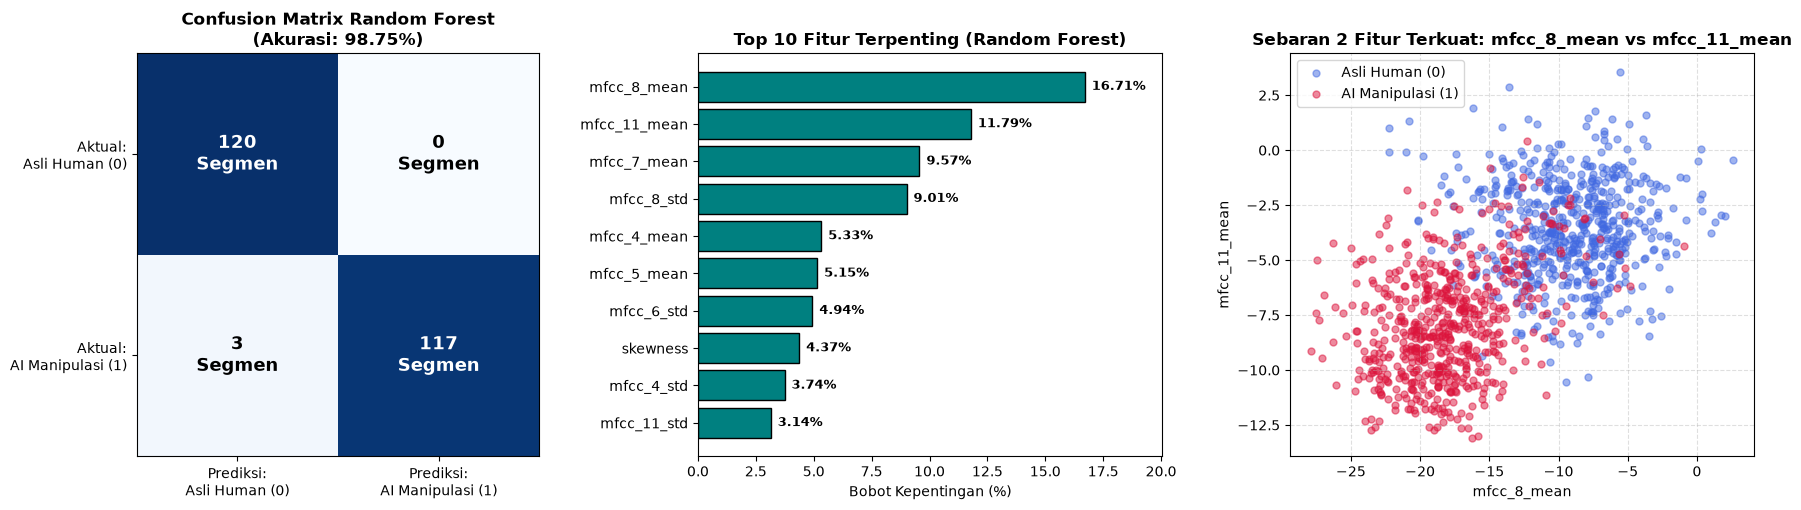

In [5]:
csv_path = '../../data/dataset_audio_kaggle/fitur_audio_5s.csv'
df_5s = pd.read_csv(csv_path)

kolom_meta  = [c for c in ['id_sampel', 'file_induk', 'blok_10s', 'segmen_5s', 'segmen_ke', 'durasi_detik', 'kelas', 'label'] if c in df_5s.columns]
kolom_fitur = [c for c in df_5s.columns if c not in kolom_meta]

# ==============================================================
# 1. CEK MISSING VALUE & DUPLIKASI DATA (SEGMEN 5 DETIK)
# ==============================================================
print('==============================================================')
print('1. PENGECEKAN KUALITAS TABEL fitur_audio_5s.csv')
print('==============================================================')
print(f'Total Baris & Kolom          : {df_5s.shape[0]} baris x {df_5s.shape[1]} kolom ({len(kolom_fitur)} fitur audio)')
print(f'Jumlah Kelas Asli (label=0)  : {(df_5s["label"] == 0).sum()} segmen')
print(f'Jumlah Kelas AI (label=1)    : {(df_5s["label"] == 1).sum()} segmen')
print(f'Jumlah Missing Value (NaN)   : {df_5s[kolom_fitur].isna().sum().sum()}')
print(f'Jumlah Baris Duplikat        : {df_5s.duplicated(subset=kolom_fitur).sum()}')

# ==============================================================
# 2. TOP 10 FITUR AUDIO PALING BERPENGARUH (KORELASI KE LABEL)
# ==============================================================
print('\n==============================================================')
print('2. TOP 10 FITUR AUDIO PALING BERPENGARUH (SEGMEN 5 DETIK)')
print('==============================================================')
korelasi = df_5s[kolom_fitur].apply(lambda x: x.corr(df_5s['label'])).abs().sort_values(ascending=False)
df_top_kor = pd.DataFrame({
    'Fitur Audio': korelasi.head(10).index,
    'Korelasi |r|': korelasi.head(10).values.round(4),
    'Mean Asli (0)': [round(df_5s[df_5s['label']==0][f].mean(), 4) for f in korelasi.head(10).index],
    'Mean AI (1)':   [round(df_5s[df_5s['label']==1][f].mean(), 4) for f in korelasi.head(10).index]
})
print(df_top_kor.to_string(index=False))

# ==============================================================
# 3. SPLIT TRAIN (80%) & TEST (20%) + NORMALISASI STANDARDSCALER
# ==============================================================
daftar_file_unik = sorted(df_5s['file_induk'].unique())  # 100 nomor file induk per kelas
train_files, test_files = train_test_split(daftar_file_unik, test_size=0.20, random_state=42)

df_train = df_5s[df_5s['file_induk'].isin(train_files)].copy()
df_test  = df_5s[df_5s['file_induk'].isin(test_files)].copy()

X_train = df_train[kolom_fitur].values
y_train = df_train['label'].values
X_test  = df_test[kolom_fitur].values
y_test  = df_test['label'].values

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ==============================================================
# 4. TRAINING & EVALUASI MODEL RANDOM FOREST (SEGMEN 5 DETIK)
# ==============================================================
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)

y_pred = rf_model.predict(X_test_scaled)
acc  = accuracy_score(y_test, y_pred) * 100
prec = precision_score(y_test, y_pred) * 100
rec  = recall_score(y_test, y_pred) * 100
f1   = f1_score(y_test, y_pred) * 100
cm   = confusion_matrix(y_test, y_pred)

print('\n==============================================================')
print('3. HASIL EVALUASI MODEL RANDOM FOREST (SEGMEN 5 DETIK)')
print('==============================================================')
print(f'Jumlah Data Training (80%)   : {len(X_train)} segmen (dari 160 file induk)')
print(f'Jumlah Data Testing  (20%)   : {len(X_test)} segmen (dari 40 file induk)')
print(f'Accuracy                     : {acc:.2f}% ({int(np.sum(y_test == y_pred))}/{len(y_test)} segmen benar)')
print(f'Precision                    : {prec:.2f}%')
print(f'Recall                       : {rec:.2f}%')
print(f'F1-Score                     : {f1:.2f}%')
print('\nConfusion Matrix:')
df_cm = pd.DataFrame(
    cm,
    index=['Aktual: Asli Human (0)', 'Aktual: AI Manipulasi (1)'],
    columns=['Prediksi: Asli Human (0)', 'Prediksi: AI Manipulasi (1)']
)
print(df_cm)

# ==============================================================
# 5. TOP 10 FEATURE IMPORTANCE RANDOM FOREST
# ==============================================================
print('\n==============================================================')
print('4. TOP 10 FITUR TERPENTING PADA MODEL RANDOM FOREST')
print('==============================================================')
importances = pd.Series(rf_model.feature_importances_, index=kolom_fitur).sort_values(ascending=False)
df_imp = pd.DataFrame({
    'Peringkat': range(1, 11),
    'Nama Fitur': importances.head(10).index,
    'Bobot Kepentingan (%)': (importances.head(10).values * 100).round(2)
})
print(df_imp.to_string(index=False))

# ==============================================================
# 6. VISUALISASI TAHAP 3: CONFUSION MATRIX, FEATURE IMPORTANCE, & DISTRIBUSI FITUR
# ==============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Plot 1: Confusion Matrix Heatmap
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_title(f'Confusion Matrix Random Forest\n(Akurasi: {acc:.2f}%)', fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Prediksi:\nAsli Human (0)', 'Prediksi:\nAI Manipulasi (1)'])
axes[0].set_yticklabels(['Aktual:\nAsli Human (0)', 'Aktual:\nAI Manipulasi (1)'])
for i in range(2):
    for j in range(2):
        warna_teks = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        axes[0].text(j, i, f'{cm[i, j]}\nSegmen', ha='center', va='center', color=warna_teks, fontsize=13, fontweight='bold')

# Plot 2: Top 10 Feature Importance (Random Forest)
top10_imp = importances.head(10)[::-1] * 100
bars = axes[1].barh(top10_imp.index, top10_imp.values, color='teal', edgecolor='black')
axes[1].set_title('Top 10 Fitur Terpenting (Random Forest)', fontweight='bold')
axes[1].set_xlabel('Bobot Kepentingan (%)')
axes[1].set_xlim(0, max(top10_imp.values) * 1.2)
for bar in bars:
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.2f}%', va='center', fontsize=9, fontweight='bold')

# Plot 3: Sebaran 2 Fitur Paling Menentukan (mfcc_8_mean vs mfcc_11_mean)
asli_df = df_5s[df_5s['label'] == 0]
ai_df   = df_5s[df_5s['label'] == 1]
axes[2].scatter(asli_df['mfcc_8_mean'], asli_df['mfcc_11_mean'], alpha=0.5, color='royalblue', label='Asli Human (0)', s=25)
axes[2].scatter(ai_df['mfcc_8_mean'], ai_df['mfcc_11_mean'], alpha=0.5, color='crimson', label='AI Manipulasi (1)', s=25)
axes[2].set_title('Sebaran 2 Fitur Terkuat: mfcc_8_mean vs mfcc_11_mean', fontweight='bold')
axes[2].set_xlabel('mfcc_8_mean')
axes[2].set_ylabel('mfcc_11_mean')
axes[2].grid(True, linestyle='--', alpha=0.4)
axes[2].legend()

plt.tight_layout()
plt.show()

---
# Tahap 4: Penyimpanan Model (`model_voice_rf_5s.pkl`) & Uji Prediksi Suara
Pada tahap ini kita membungkus model **Random Forest**, **StandardScaler**, dan daftar **48 nama fitur audio** ke dalam satu file **`model_voice_rf_5s.pkl`** menggunakan `joblib` agar siap digunakan langsung oleh aplikasi web **Flask** (`frontend/app.py`), sekaligus menguji prediksinya beserta visualisasi *Confidence Score*.

1. PENYIMPANAN PAKET MODEL (.PKL) UNTUK DEPLOYMENT FLASK
File Model Tersimpan : model_voice_rf_5s.pkl (1486.22 KB)
Jumlah Fitur Audio   : 48 fitur (Segmen @ 5 Detik, SR 16.000 Hz)
Akurasi Model        : 98.75% | F1-Score: 98.73%

2. UJI COBA PREDIKSI FILE AUDIO (PER SEGMEN 5 DETIK & VOTING)
File Uji 1 (Asli) : audio_084.wav -> Prediksi: Suara Manusia Asli (Human Voice) | Confidence: 94.00%
File Uji 2 (AI)   : audio_084.wav -> Prediksi: Suara Manipulasi AI (AI-Generated Voice) | Confidence: 91.58%


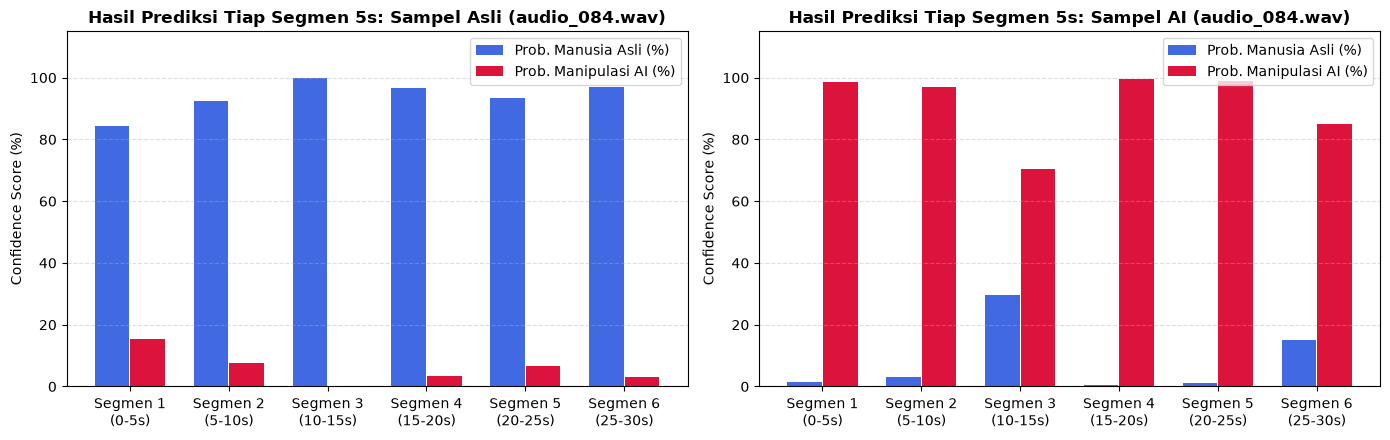

In [6]:
paket_model = {
    'model': rf_model,
    'scaler': scaler,
    'kolom_fitur': kolom_fitur,
    'sr': 16000,
    'durasi_segmen': 5,
    'label_map': {
        0: 'Suara Manusia Asli (Human Voice)',
        1: 'Suara Manipulasi AI (AI-Generated Voice)'
    },
    'metrics': {
        'accuracy': round(acc, 2),
        'precision': round(prec, 2),
        'recall': round(rec, 2),
        'f1_score': round(f1, 2)
    },
    'mean_asli': df_5s[df_5s['label'] == 0][kolom_fitur].mean().to_dict(),
    'mean_ai': df_5s[df_5s['label'] == 1][kolom_fitur].mean().to_dict()
}

pkl_path = 'model_voice_rf_5s.pkl'
joblib.dump(paket_model, pkl_path)

print('==============================================================')
print('1. PENYIMPANAN PAKET MODEL (.PKL) UNTUK DEPLOYMENT FLASK')
print('==============================================================')
print(f'File Model Tersimpan : {pkl_path} ({os.path.getsize(pkl_path)/1024:.2f} KB)')
print(f'Jumlah Fitur Audio   : {len(kolom_fitur)} fitur (Segmen @ 5 Detik, SR 16.000 Hz)')
print(f'Akurasi Model        : {acc:.2f}% | F1-Score: {f1:.2f}%')

# Fungsi uji prediksi file suara dengan memotong per 5 detik
def prediksi_file_wav(wav_path, bundle):
    y_audio, sr_in = librosa.load(wav_path, sr=bundle['sr'], mono=True)
    sampel_5s = bundle['durasi_segmen'] * bundle['sr']
    if len(y_audio) < sampel_5s:
        y_audio = np.pad(y_audio, (0, sampel_5s - len(y_audio)))

    jumlah_segmen = max(1, len(y_audio) // sampel_5s)
    f0_all = librosa.yin(y_audio[:jumlah_segmen * sampel_5s], fmin=50, fmax=400, sr=bundle['sr'])
    total_f0 = len(f0_all)

    list_fitur = []
    for idx in range(jumlah_segmen):
        y_seg = y_audio[idx * sampel_5s : (idx + 1) * sampel_5s]
        f0_seg = f0_all[int(idx * total_f0 / jumlah_segmen) : int((idx + 1) * total_f0 / jumlah_segmen)]
        d_fitur = ekstrak_fitur_segmen(y_seg, bundle['sr'], f0_seg)
        list_fitur.append([d_fitur[k] for k in bundle['kolom_fitur']])

    X_input = bundle['scaler'].transform(np.array(list_fitur))
    proba_segmen = bundle['model'].predict_proba(X_input)  # [prob_asli, prob_ai] per segmen
    mean_proba = np.mean(proba_segmen, axis=0)
    label_akhir = int(np.argmax(mean_proba))
    return label_akhir, mean_proba, proba_segmen

contoh_asli = os.path.join(base_dir, 'asli_human', test_files[0])
contoh_ai   = os.path.join(base_dir, 'ai_manipulasi', test_files[0])

lbl_asli, prob_asli, seg_asli = prediksi_file_wav(contoh_asli, paket_model)
lbl_ai, prob_ai, seg_ai       = prediksi_file_wav(contoh_ai, paket_model)

print('\n==============================================================')
print('2. UJI COBA PREDIKSI FILE AUDIO (PER SEGMEN 5 DETIK & VOTING)')
print('==============================================================')
print(f'File Uji 1 (Asli) : {test_files[0]} -> Prediksi: {paket_model["label_map"][lbl_asli]} | Confidence: {prob_asli[lbl_asli]*100:.2f}%')
print(f'File Uji 2 (AI)   : {test_files[0]} -> Prediksi: {paket_model["label_map"][lbl_ai]} | Confidence: {prob_ai[lbl_ai]*100:.2f}%')

# ==============================================================
# 3. VISUALISASI TAHAP 4: GRAFIK CONFIDENCE PER SEGMEN 5 DETIK
# ==============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
seg_labels = [f'Segmen {i+1}\n({i*5}-{(i+1)*5}s)' for i in range(len(seg_asli))]
x_pos = np.arange(len(seg_asli))

# Plot 1: Probabilitas per Segmen pada File Uji Suara Asli
axes[0].bar(x_pos - 0.18, seg_asli[:, 0] * 100, width=0.35, color='royalblue', label='Prob. Manusia Asli (%)')
axes[0].bar(x_pos + 0.18, seg_asli[:, 1] * 100, width=0.35, color='crimson', label='Prob. Manipulasi AI (%)')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(seg_labels)
axes[0].set_ylim(0, 115)
axes[0].set_ylabel('Confidence Score (%)')
axes[0].set_title(f'Hasil Prediksi Tiap Segmen 5s: Sampel Asli ({test_files[0]})', fontweight='bold')
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# Plot 2: Probabilitas per Segmen pada File Uji Suara AI
axes[1].bar(x_pos - 0.18, seg_ai[:, 0] * 100, width=0.35, color='royalblue', label='Prob. Manusia Asli (%)')
axes[1].bar(x_pos + 0.18, seg_ai[:, 1] * 100, width=0.35, color='crimson', label='Prob. Manipulasi AI (%)')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(seg_labels)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Confidence Score (%)')
axes[1].set_title(f'Hasil Prediksi Tiap Segmen 5s: Sampel AI ({test_files[0]})', fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()